# Brew Room Christmas Campaign: Did it work, and who bought?

Two questions, answered with Python:

1. **Was the jump in daily revenue during the campaign bigger than normal day-to-day ups and downs?** (a statistical test)
2. **Which customers drove the revenue?** (RFM segmentation)

**About the data:** the real sales data is confidential, so this notebook uses the simulated dataset in `../data`, built around a few real headline figures (see the project README). Treat the numbers as a demonstration of method, not as the business's real results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from scipy import stats

DATA = Path("..") / "data"

# Chart style: quiet grid, thin marks, one accent colour
BLUE, MUTED = "#2a78d6", "#898781"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 10, "text.color": INK,
})
rupees = lambda x, _=None: f"\u20b9{x:,.0f}"


## Part 1: Was the campaign lift real?

I compare average daily revenue for the 12 days before the campaign (Dec 1-12) with the 13 days of the campaign (Dec 13-25), across all products.

In [2]:
sales = pd.read_csv(DATA / "daily_sales.csv", parse_dates=["date"])

# One row per day: total revenue across all products
daily = sales.groupby(["date", "campaign_period"], as_index=False)["revenue"].sum()
daily["period"] = np.where(daily["campaign_period"] == "Pre-Campaign", "Before", "During campaign")

before = daily.loc[daily["period"] == "Before", "revenue"]
during = daily.loc[daily["period"] == "During campaign", "revenue"]

summary = daily.groupby("period")["revenue"].agg(days="count", mean="mean", median="median", std="std").round(0)
summary.loc[["Before", "During campaign"]]

,days,mean,median,std
period,,,,
Before,12,20897.0,20816.0,3498.0
During campaign,13,79214.0,73774.0,19589.0


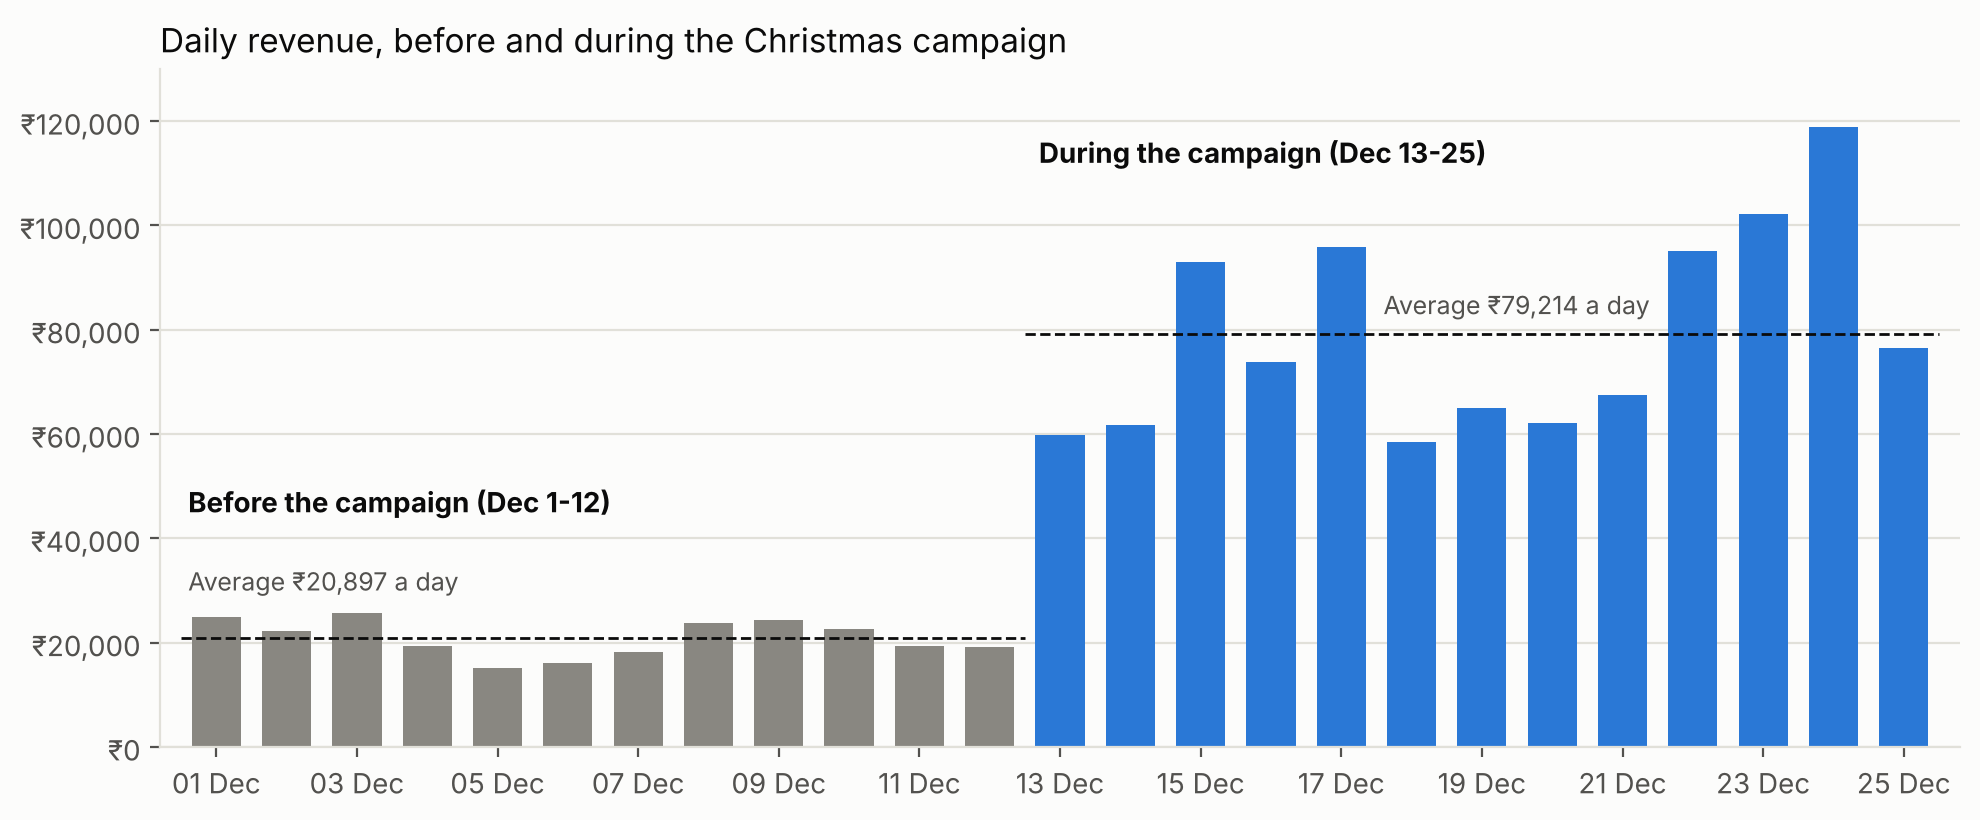

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = np.where(daily["period"] == "Before", MUTED, BLUE)
ax.bar(daily["date"], daily["revenue"], color=colors, width=0.7)

# Average lines, labelled directly on the chart (two groups, so no legend box is needed)
x0, x1 = daily["date"].min(), daily["date"].max()
split = daily.loc[daily["period"] == "During campaign", "date"].min()
edge = split - pd.Timedelta(days=0.5)
ax.hlines(before.mean(), x0 - pd.Timedelta(days=0.5), edge, color=INK, linewidth=1, linestyles="--")
ax.hlines(during.mean(), edge, x1 + pd.Timedelta(days=0.5), color=INK, linewidth=1, linestyles="--")

# Labels placed in empty space so they never sit on a bar
ax.text(x0 - pd.Timedelta(days=0.4), 45_000, "Before the campaign (Dec 1-12)", color=INK, fontsize=10, fontweight="bold")
ax.text(x0 - pd.Timedelta(days=0.4), 30_000, f"Average {rupees(before.mean())} a day", color=INK2, fontsize=9)
ax.text(edge + pd.Timedelta(days=0.2), 112_000, "During the campaign (Dec 13-25)", color=INK, fontsize=10, fontweight="bold")
ax.text(pd.Timestamp("2023-12-18") - pd.Timedelta(days=0.4), 83_000, f"Average {rupees(during.mean())} a day", color=INK2, fontsize=9)

ax.set_title("Daily revenue, before and during the Christmas campaign", loc="left", fontsize=12, color=INK)
ax.set_ylim(0, 130_000)
ax.set_xlim(x0 - pd.Timedelta(days=0.8), x1 + pd.Timedelta(days=0.8))
ax.yaxis.set_major_formatter(rupees)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 26, 2)))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Now the tests. I use three, because each one makes different assumptions, and I want the answer to hold up under all of them:

- **Welch's t-test** compares the two averages and allows the two periods to vary by different amounts.
- **Mann-Whitney U** asks the same question without assuming a bell-curve shape.
- **A bootstrap** re-draws the days thousands of times to give a plausible range for the lift itself.

In [4]:
lift = during.mean() / before.mean() - 1

# Welch's t-test: is the difference in average daily revenue bigger than day-to-day noise?
# (Welch's version does not assume both periods vary by the same amount.)
welch = stats.ttest_ind(during, before, equal_var=False)
ci_low, ci_high = welch.confidence_interval(0.95)

# Mann-Whitney U: the same question without assuming a bell-curve shape
mwu = stats.mannwhitneyu(during, before, alternative="greater")

# Bootstrap: resample the days many times to get a range for the lift itself
rng = np.random.default_rng(42)
boot = np.array([
    rng.choice(during, len(during)).mean() / rng.choice(before, len(before)).mean() - 1
    for _ in range(10_000)
])
boot_low, boot_high = np.percentile(boot, [2.5, 97.5])

print(f"Average daily revenue before : {before.mean():>10,.0f}")
print(f"Average daily revenue during : {during.mean():>10,.0f}")
print(f"Lift                         : {lift:>10.0%}   (95% bootstrap range {boot_low:.0%} to {boot_high:.0%})")
print(f"Difference, 95% CI           : {during.mean() - before.mean():>10,.0f}  ({ci_low:,.0f} to {ci_high:,.0f})")
print(f"Welch t-test                 : t = {welch.statistic:.1f}, p = {welch.pvalue:.1e}")
print(f"Mann-Whitney U (one-sided)   : p = {mwu.pvalue:.1e}")

Average daily revenue before :     20,897
Average daily revenue during :     79,214
Lift                         :       279%   (95% bootstrap range 222% to 344%)
Difference, 95% CI           :     58,317  (46,362 to 70,272)
Welch t-test                 : t = 10.6, p = 1.1e-07
Mann-Whitney U (one-sided)   : p = 1.2e-05


### What this shows

- Average daily revenue went from about **₹20,900** to about **₹79,200**, a lift of roughly **280%**. The bootstrap range for the lift is about **220% to 340%**.
- All three tests agree that the gap is far larger than normal day-to-day variation (Welch p about 0.0000001, Mann-Whitney p about 0.00001). The average campaign day brought in **₹46,000 to ₹70,000 more** than the average pre-campaign day (95% confidence interval).

### What this does not show

- **It does not prove the campaign alone caused the lift.** There is no control group, and the campaign ran in Christmas week, when gifting spend rises anyway. A fair claim is "revenue rose sharply during the campaign", not "the campaign created 280% more revenue".
- Days are not fully independent (weekends and the run-up to Dec 24 move together), and the sample is only 25 days. The tests are a sanity check on the size of the gap, not a precise measurement.
- The data is simulated, so the result reflects how I built the data. The method is what carries over to real data.

## Part 2: Who drove the revenue? RFM segmentation

RFM scores every customer on three things:

- **Recency:** how recently they last bought
- **Frequency:** how many times they bought
- **Monetary:** how much they spent in total

Each is scored 1 to 5 (5 is best), and the R and F scores are combined into simple segments. The orders come from `transactions.csv`, a simulated split of the daily sales into individual purchases by customer. It adds up exactly to the daily sales figures.

In [5]:
orders = pd.read_csv(DATA / "transactions.csv", parse_dates=["date"])

# Snapshot date: the day after the last order, so the most recent buyers have recency = 1
snapshot = orders["date"].max() + pd.Timedelta(days=1)

rfm = orders.groupby("customer_id").agg(
    recency=("date", lambda d: (snapshot - d.max()).days),   # days since last purchase
    frequency=("order_id", "count"),                         # number of purchases
    monetary=("amount", "sum"),                              # total spend
)

def quintile_score(values, higher_is_better=True):
    """Score 1-5 by rank. Ranking first avoids errors when many customers tie."""
    ranks = values.rank(method="first", ascending=higher_is_better)
    return pd.qcut(ranks, 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["R"] = quintile_score(rfm["recency"], higher_is_better=False)  # recent = high score
rfm["F"] = quintile_score(rfm["frequency"])
rfm["M"] = quintile_score(rfm["monetary"])

def segment(row):
    if row.R >= 4 and row.F >= 4:
        return "Champions"
    if row.R >= 3 and row.F >= 3:
        return "Loyal"
    if row.R <= 2 and row.F >= 3:
        return "At risk"
    if row.R >= 4 and row.F <= 2:
        return "New or recent"
    return "Occasional"

rfm["segment"] = rfm.apply(segment, axis=1)

segments = rfm.groupby("segment").agg(
    customers=("segment", "size"),
    avg_days_since_last=("recency", "mean"),
    avg_purchases=("frequency", "mean"),
    avg_spend=("monetary", "mean"),
    revenue=("monetary", "sum"),
)
segments["pct_of_customers"] = segments["customers"] / segments["customers"].sum() * 100
segments["pct_of_revenue"] = segments["revenue"] / segments["revenue"].sum() * 100
segments = segments.sort_values("revenue", ascending=False).round(1)
segments

,customers,avg_days_since_last,avg_purchases,avg_spend,revenue,pct_of_customers,pct_of_revenue
segment,,,,,,,
Champions,70,1.2,18.7,9949.2,696441,24.8,54.4
Loyal,57,1.9,8.4,4564.0,260148,20.2,20.3
At risk,42,4.7,8.0,3820.3,160453,14.9,12.5
Occasional,90,7.4,2.5,1320.0,118798,31.9,9.3
New or recent,23,1.6,3.1,1943.8,44708,8.2,3.5


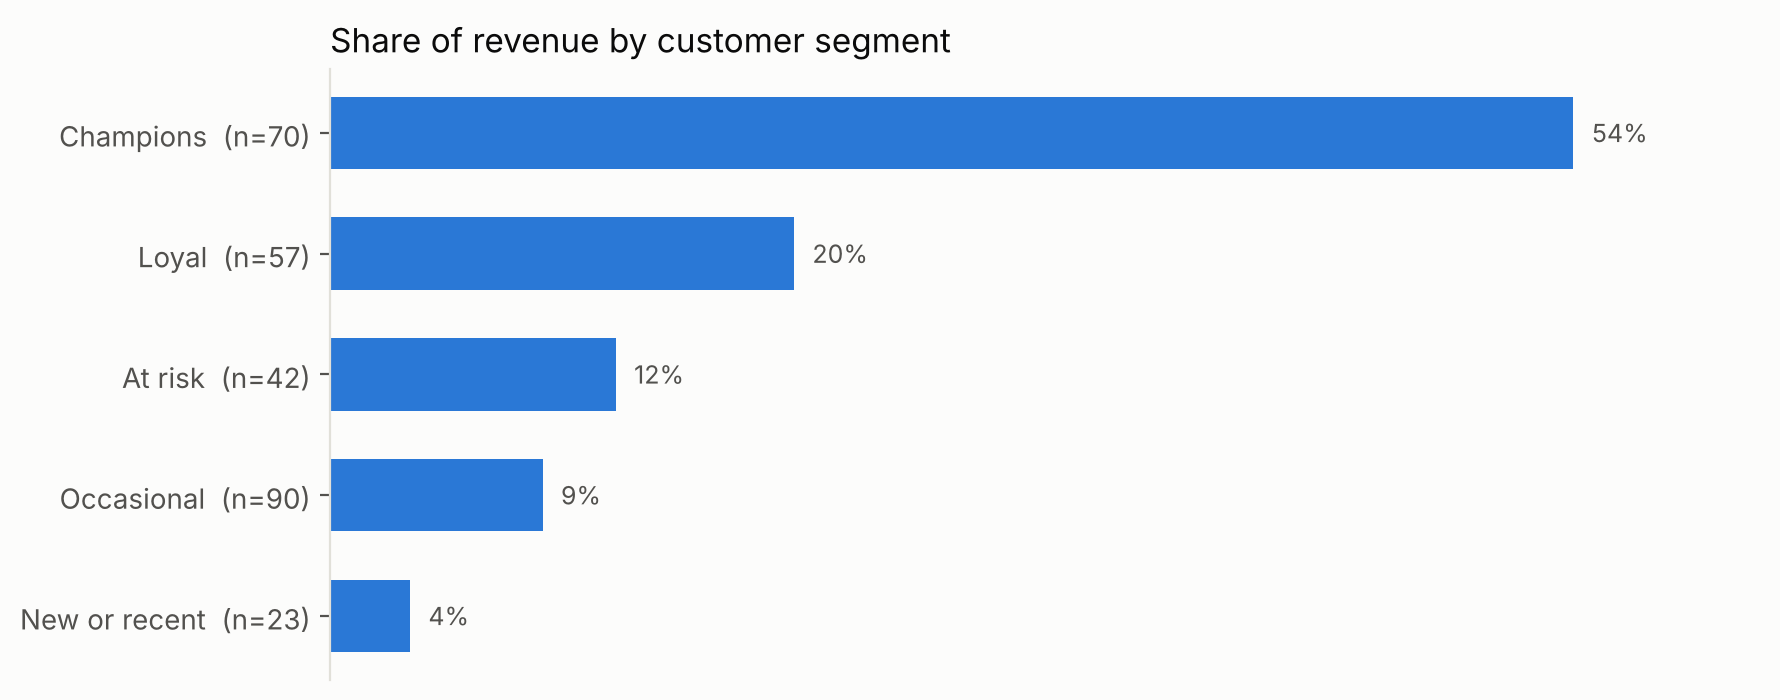

In [6]:
plot = segments.sort_values("pct_of_revenue")
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.barh([f"{name}  (n={n})" for name, n in zip(plot.index, plot["customers"])],
               plot["pct_of_revenue"], color=BLUE, height=0.6)
for bar, value in zip(bars, plot["pct_of_revenue"]):
    ax.text(value + 0.8, bar.get_y() + bar.get_height() / 2, f"{value:.0f}%", va="center", color=INK2, fontsize=9)
ax.set_title("Share of revenue by customer segment", loc="left", fontsize=12, color=INK)
ax.set_xlim(0, plot["pct_of_revenue"].max() * 1.15)
ax.xaxis.set_visible(False)
ax.grid(False)
ax.spines["bottom"].set_visible(False)
plt.tight_layout()
plt.show()

### What this shows

- **Champions** (recent and frequent buyers) are about a quarter of customers (25%) but bring in **over half of revenue (54%)**.
- Champions and Loyal customers together are **45% of customers and about 75% of revenue**.
- **At risk** customers (they bought often earlier but not recently) are 15% of customers and 12% of revenue. They are the group to win back first, for example with a loyalty-card reminder or a New Year offer.
- **Occasional** buyers are the biggest group (32% of customers) but only 9% of revenue.

### Limits

- The data covers only 25 days, so "recency" is measured in days, and "at risk" here means a few days without a purchase. With real data I would use a longer window, such as 6 to 12 months.
- The segment rules (for example, Champions need both R and F of 4 or more) are my own choices. Moving the cut-offs would move customers between segments.

## What I would do next with real data

- Add a control (for example, a similar café or product line that did not run the campaign) to separate the campaign effect from the Christmas effect.
- Link customers to loyalty-card members to see whether members behave like Champions.
- Run RFM over a longer period and track how customers move between segments month to month.